### Задание 1 (8 баллов + 0.5)

Скачайте вот этот датасет - ("MERA-evaluation/MERA", "multiq"). Так как обучать ничего не придется возьмите train split. Возьмите оттуда 25 примеров (случайных, а не первых). 

Преобразуйте колонку instruction, заменив переменные вроде `{support_text}` на реальные значения из других колонок, чтобы получился готовый промпт (инпут для модели).

#### Метрика (2 балла)

Напишите две метрики для оценки правильных ответов: 1) exact match и 2) F1 по леммам. Для первой просто добавьте базовую предобработку вроде удаления пунктуации и регистра и просто сопоставьте строки между собой. Для второй к базовой предобработке добавьте токенизацию и лемматизацию, а поверх лемм рассчитайте F1 метрику (подсказка - precision можно рассчитать посчитав какой процент лемм в предсказанном ответе совпадает с правильным ответом). 

Рассчитайте метрики на простом бейзлайне (например, можете попробовать взять самый частотный биграмм из промпта в качестве ответа). Можно получить +0.5 балла за неочевидный ненулевой бейзлайн.

#### Эксперимент 1 (2 балла)
Возьмите какую-нибудь не очень большую модель с huggingface (например, `Qwen/Qwen3.5-0.8B`, но можно и любую другую, которая умеет отвечать на инструкции и поддерживает thinking). Преобразуйте промпты из датасета в формат `messages = [{"role": "user", "content": prompt}]` с помощью чат темплейта этой модели. 
Сгенерируйте ответы модели на полученных данных (25 примеров). На этом шаге не используйте thinking. Поставьте max_new_tokens на не очень большое значения, чтобы генерация не занимала слишком много времени. 
Оцените качество ответов с помощью двух метрик.

#### Эксперимент 2 (1 балла)
К первому эксперименту добавьте какой-то system prompt, который по вашему должен помочь модели справится с результатом. Можете проанализировать ошибки из первого задания и написать инструкции на основе этого. 
Сгенерируйте ответы с точно такими же параметрами как и в эксперименте 1. 
Оцените качество ответов с помощью двух метрик.

#### Эсперимент 3 (3 балла)
На этом шаге включите thinking в модели и сгенерируйте предсказания (system prompt вы можете использовать по вашему желанию).
На этом шаге у вас будет несколько сложностей, которые нужно решить: 
1) генерацию модели нельзя использовать напрямую, сначала нужно отделить thinking блок от самого ответа. Добавьте пост обработку
2) thinking может занять достаточно много токенов и его нужно ограничить, но при этом вам нужно, чтобы модель выдала и сам ответ, а не только незаконченные размышлений. Выберите max_new_tokens с рассчетом на (thinking_tokens + answer_tokens). Сначала запустите первую генерацию с thinking_tokens, затем проверьте, что в ответе содержится </think> тэг, который означает, что модель закончила думать (еще удобно использовать `stop_strings` в huggingface generation параметрах, чтобы заканчивать как только появился нужный токен). И если тэг есть, то просто запустите вторую генерацию с max_new_tokens (как продолжение уже накопившегося) или же поставьте </think> тэг вручную (обрубив размышление) и запустите вторую генерацию c answer_tokens. 


In [2]:
%pip install datasets

<class 'ValueError'>: Can't find a pure Python 3 wheel for 'pyarrow>=24.0.0'.
See: https://pyodide.org/en/stable/usage/faq.html#why-can-t-micropip-find-a-pure-python-wheel-for-a-package
You can use `await micropip.install(..., keep_going=True)` to get a list of all packages with missing wheels.

In [ ]:
import pandas as pd
import random
import re
import string
from datasets import load_dataset
from collections import Counter

dataset = load_dataset("MERA-evaluation/MERA", "multiq", split="train")
random.seed(42)  # для воспроизводимости
indices = random.sample(range(len(dataset)), 25)
subset = dataset.select(indices)

#Преобразование промптов
def format_prompt(example):
    # Заменяем плейсхолдеры в instruction на значения из inputs
    prompt = example['instruction']
    for key, value in example['inputs'].items():
        prompt = prompt.replace(f"{{{key}}}", str(value))
    return prompt

df = subset.to_pandas()
df['prompt'] = df.apply(format_prompt, axis=1)

In [ ]:
import pymorphy3
from nltk.tokenize import word_tokenize
import nltk
nltk.download('punkt_tab', quiet=True)

morph = pymorphy3.MorphAnalyzer()

def normalize_text(text):
    """Базовая предобработка: нижний регистр, удаление пунктуации."""
    text = str(text).lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return " ".join(text.split())

def exact_match(gold, pred):
    return normalize_text(gold) == normalize_text(pred)

def get_lemmas(text):
    """Токенизация и лемматизация."""
    tokens = word_tokenize(normalize_text(text))
    return [morph.parse(token)[0].normal_form for token in tokens]

def f1_lemmas(gold, pred):
    gold_lemmas = get_lemmas(gold)
    pred_lemmas = get_lemmas(pred)
    
    if len(gold_lemmas) == 0 or len(pred_lemmas) == 0:
        return 0.0
    
    common = Counter(gold_lemmas) & Counter(pred_lemmas)
    num_same = sum(common.values())
    
    if num_same == 0:
        return 0.0
    
    precision = num_same / len(pred_lemmas)
    recall = num_same / len(gold_lemmas)
    f1 = (2 * precision * recall) / (precision + recall)
    return f1

In [ ]:
def extract_most_frequent_ngram(text, n=1):
    """Берет самый частотный n-грамм из текста (исключая стоп-слова)."""
    tokens = word_tokenize(normalize_text(text))
    # Простой фильтр стоп-слов
    stops = {'в', 'на', 'и', 'с', 'по', 'из', 'к', 'у', 'о', 'что', 'как', 'это', 'или', 'для'}
    tokens = [t for t in tokens if t not in stops]
    ngrams = [' '.join(tokens[i:i+n]) for i in range(len(tokens)-n+1)]
    if not ngrams:
        return ""
    return Counter(ngrams).most_common(1)[0][0]

# Генерируем бейзлайн-предсказания
df['baseline_pred'] = df['prompt'].apply(lambda x: extract_most_frequent_ngram(x, n=1))

em_scores = [exact_match(g, p) for g, p in zip(df['outputs'], df['baseline_pred'])]
f1_scores = [f1_lemmas(g, p) for g, p in zip(df['outputs'], df['baseline_pred'])]

print(f"Baseline EM: {sum(em_scores)/len(em_scores):.4f}")
print(f"Baseline F1: {sum(f1_scores)/len(f1_scores):.4f}")

In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

model_id = "Qwen/Qwen3.5-0.8B"
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16, device_map="auto")

def generate_response(prompt, system_prompt=None, enable_thinking=False, max_new_tokens=128):
    messages = []
    if system_prompt:
        messages.append({"role": "system", "content": system_prompt})
    messages.append({"role": "user", "content": prompt})
    
    text = tokenizer.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True,
        enable_thinking=enable_thinking 
    )
    
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )
    response = tokenizer.decode(outputs[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    return response.strip()

# Эксперимент 1
df['pred_exp1'] = df['prompt'].apply(lambda x: generate_response(x, enable_thinking=False))

em1 = sum(exact_match(g, p) for g, p in zip(df['outputs'], df['pred_exp1'])) / len(df)
f1_1 = sum(f1_lemmas(g, p) for g, p in zip(df['outputs'], df['pred_exp1'])) / len(df)
print(f"Exp 1 (No System, No Thinking) EM: {em1:.4f}, F1: {f1_1:.4f}")

In [ ]:
SYSTEM_PROMPT = "Ты — эксперт по извлечению информации. Отвечай максимально кратко, только на русском языке, без лишних слов и объяснений. Твой ответ должен содержать только искомую сущность или число."

df['pred_exp2'] = df['prompt'].apply(lambda x: generate_response(x, system_prompt=SYSTEM_PROMPT, enable_thinking=False))

em2 = sum(exact_match(g, p) for g, p in zip(df['outputs'], df['pred_exp2'])) / len(df)
f1_2 = sum(f1_lemmas(g, p) for g, p in zip(df['outputs'], df['pred_exp2'])) / len(df)
print(f"Exp 2 (System Prompt, No Thinking) EM: {em2:.4f}, F1: {f1_2:.4f}")

In [ ]:
def generate_with_thinking(prompt, system_prompt=None, thinking_tokens=256, answer_tokens=128):
    messages = []
    if system_prompt:
        messages.append({"role": "system", "content": system_prompt})
    messages.append({"role": "user", "content": prompt})
    
    text = tokenizer.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True,
        enable_thinking=True 
    )
    
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    
    # Первая генерация: выделяем бюджет на thinking
    outputs = model.generate(
        **inputs,
        max_new_tokens=thinking_tokens,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
    )
    
    response = tokenizer.decode(outputs[0][inputs['input_ids'].shape[1]:], skip_special_tokens=False)
    
    # Постобработка: отделяем thinking от ответа
    if "</think>" in response:
        answer = response.split("</think>")[-1].strip()
    else:
        # Вторая генерация (продолжение)
        # Обрезаем prompt до текущего состояния (prompt + thinking)
        current_text = text + response + "</think>\n"
        inputs_2 = tokenizer(current_text, return_tensors="pt").to(model.device)
        outputs_2 = model.generate(
            **inputs_2,
            max_new_tokens=answer_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
        answer = tokenizer.decode(outputs_2[0][inputs_2['input_ids'].shape[1]:], skip_special_tokens=True).strip()
        
    return answer

# Запускаем с thinking (используем system prompt)
df['pred_exp3'] = df['prompt'].apply(lambda x: generate_with_thinking(x, system_prompt=SYSTEM_PROMPT))

em3 = sum(exact_match(g, p) for g, p in zip(df['outputs'], df['pred_exp3'])) / len(df)
f1_3 = sum(f1_lemmas(g, p) for g, p in zip(df['outputs'], df['pred_exp3'])) / len(df)
print(f"Exp 3 (System Prompt, With Thinking) EM: {em3:.4f}, F1: {f1_3:.4f}")

JupiterLite настоящее зло(((( вот результаты работы из google colab, но у меня код выполняется уже 1 час 15 минут и непонятно сколько ещё ждать.....я правда старалась Т-Т Т-Т Т-Т

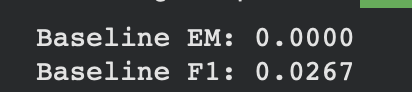

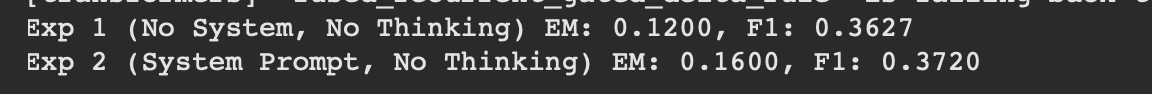

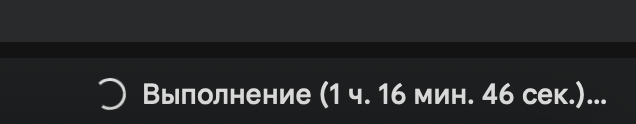

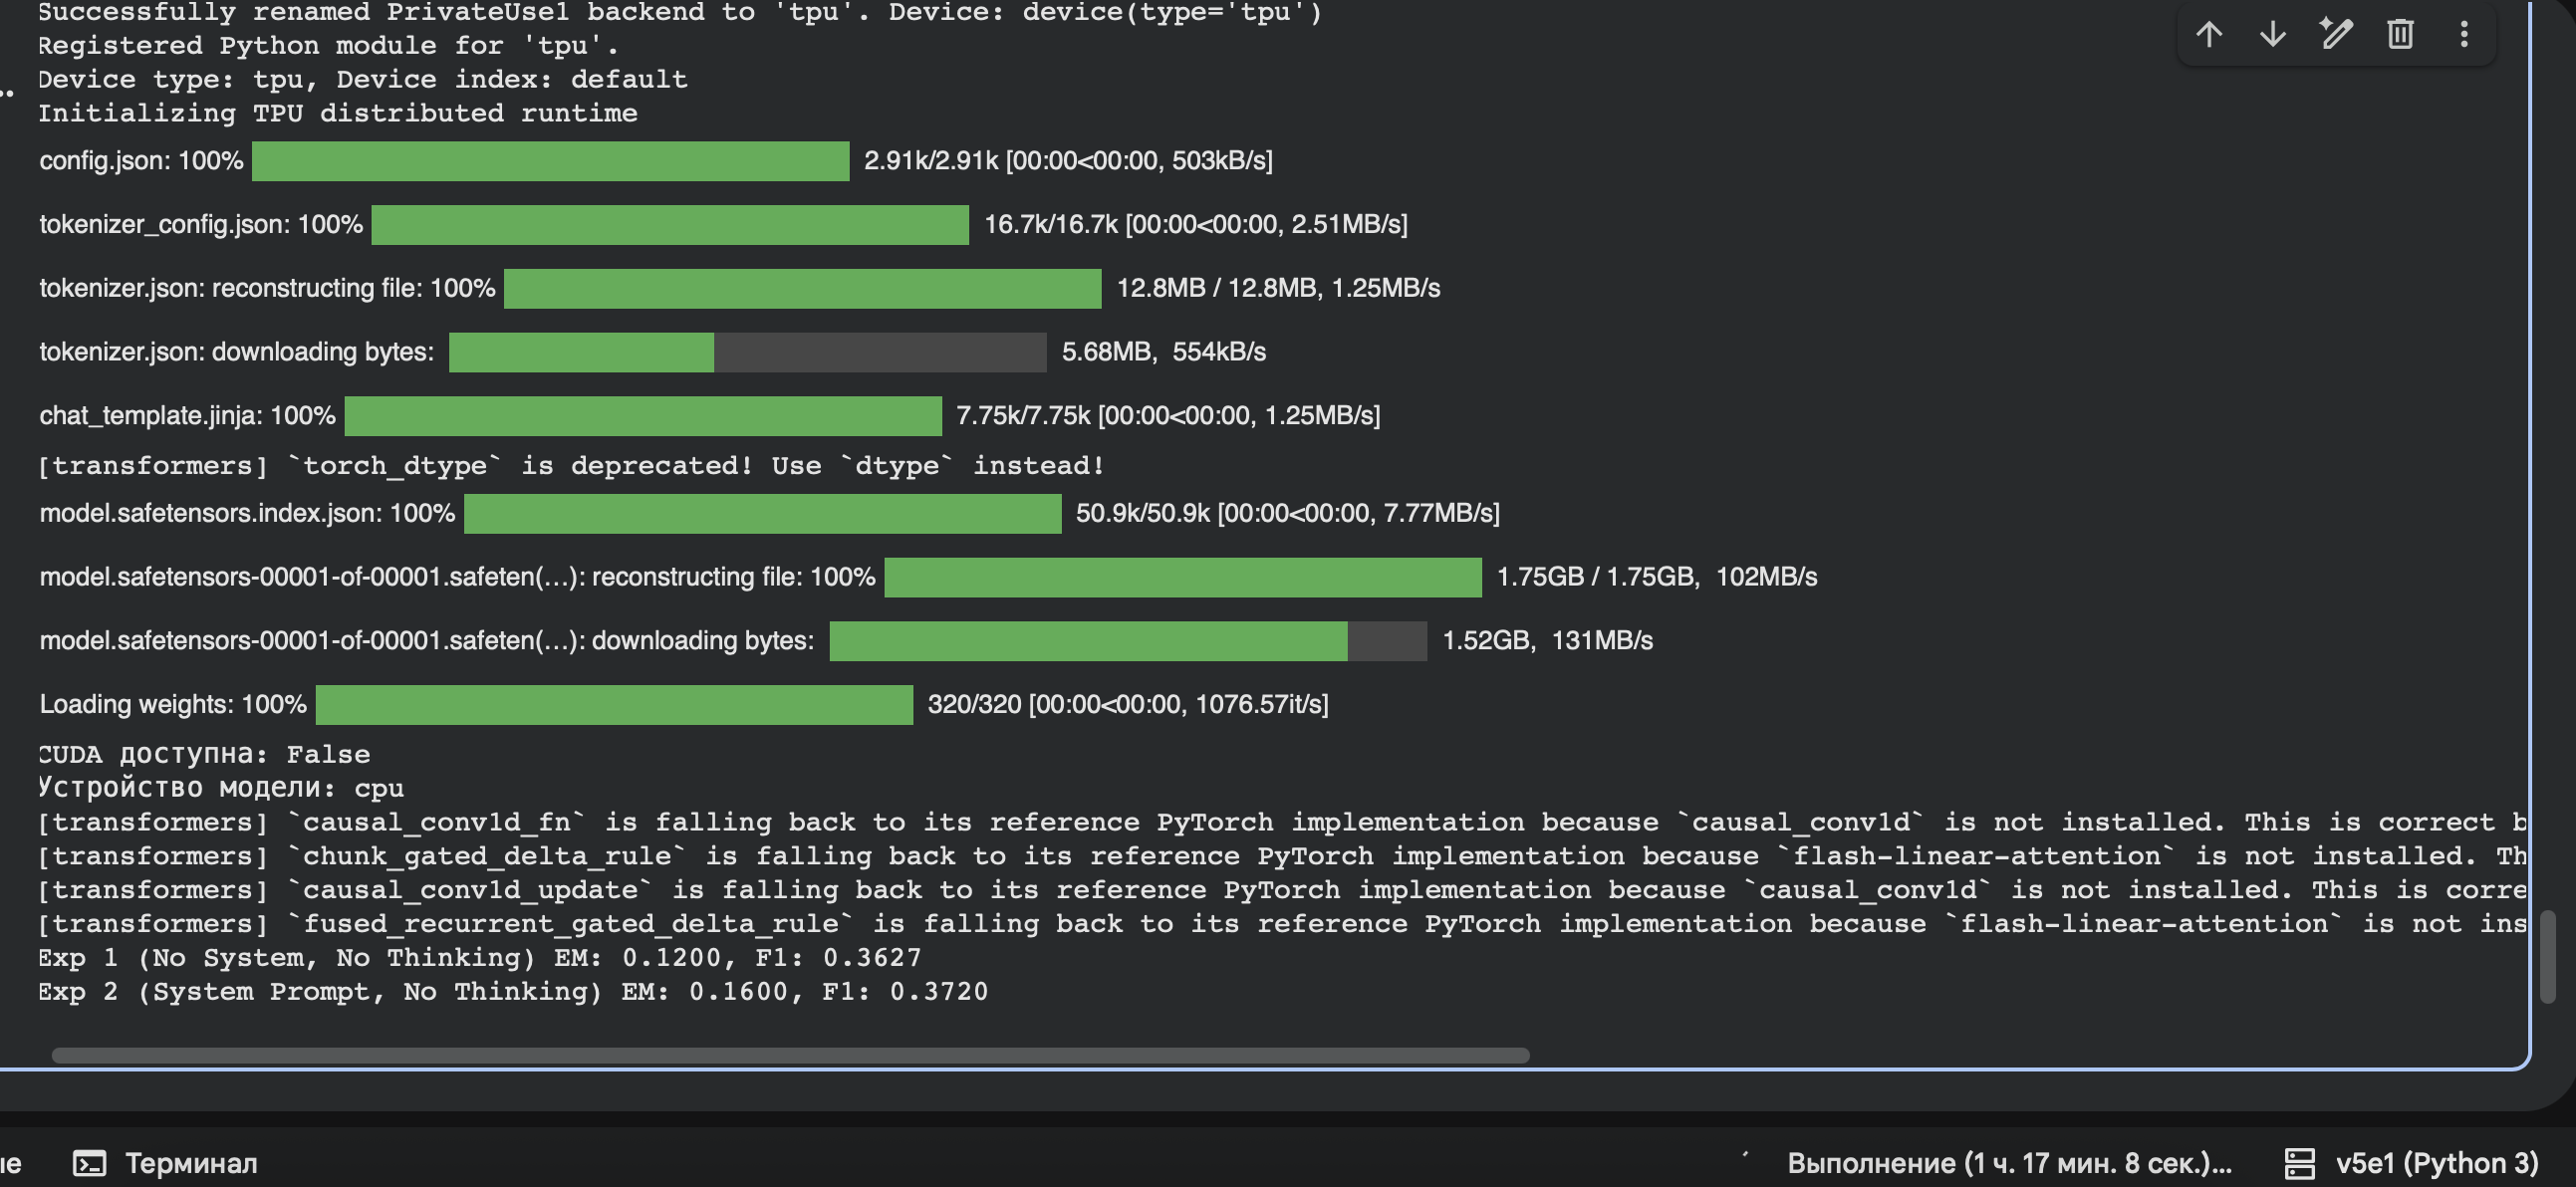